# Session 14 · Case study: tokens and semantic similarity

**Block 1, worked example.** Tokenise descriptions of goods and compare token counts across languages; compute semantic similarity between descriptions of the same goods in different languages.

Uses `sentence-transformers` and `tiktoken` from the course environment. The first run downloads `intfloat/multilingual-e5-small` (about 470 MB) and the GPT-4o tokeniser file of `tiktoken`; later runs work offline. No API key needed.

Theory: [01-lecture-embeddings-from-words-to-vectors.ipynb](01-lecture-embeddings-from-words-to-vectors.ipynb). Exercises: [session-14-exercises.ipynb](session-14-exercises.ipynb), part 1.

*Author: course team, licence CC-BY-4.0.*

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# find the repository root (the folder that contains case-study/), wherever the notebook runs
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").exists())
DATA = ROOT / "case-study" / "data"
decisions = pd.read_parquet(DATA / "train_sample.parquet")
nomenclature = pd.read_parquet(DATA / "nomenclature.parquet").set_index("heading")
print(decisions.shape)

(50000, 14)


In [2]:
import tiktoken
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("intfloat/multilingual-e5-small")
sentencepiece = model.tokenizer                     # tokeniser of the embedding model (XLM-R type)
bpe = tiktoken.get_encoding("o200k_base")           # tokeniser of GPT-4o-type models
print("input limit of the embedding model:", model.max_seq_length, "tokens")

.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7727.82it/s]

input limit of the embedding model: 512 tokens


## 1. One description, three ways of splitting it

In [3]:
text = decisions.loc[(decisions["language"] == "de") & decisions["description"].str.len().between(80, 160),
                     "description"].iloc[3]
print(text)
print("words        ", len(text.split()), text.split()[:12])
print("SentencePiece", len(sentencepiece.tokenize(text)), sentencepiece.tokenize(text)[:14])
print("BPE          ", len(bpe.encode(text)), [bpe.decode([i]) for i in bpe.encode(text)][:14])

Angaben:
keramische Mikrohohlkugeln, OMEGA-SPHERES. Sonstiges: siehe vertrauliche Daten.

Befund:
Ähnliches geblähtes mineralisches Erzeugnis
words         13 ['Angaben:', 'keramische', 'Mikrohohlkugeln,', 'OMEGA-SPHERES.', 'Sonstiges:', 'siehe', 'vertrauliche', 'Daten.', 'Befund:', 'Ähnliches', 'geblähtes', 'mineralisches']
SentencePiece 44 ['▁Angaben', ':', '▁keram', 'ische', '▁Mikro', 'ho', 'hl', 'ku', 'gel', 'n', ',', '▁OM', 'EGA', '-']
BPE           46 ['Ang', 'aben', ':\n', 'ker', 'am', 'ische', ' Mikro', 'ho', 'hl', 'k', 'ug', 'eln', ',', ' O']


## 2. Token counts of 2,000 descriptions by language

In [4]:
sample = decisions.sample(2000, random_state=0)
counts = pd.DataFrame({
    "language": sample["language"],
    "characters": sample["description"].str.len(),
    "words": sample["description"].str.split().str.len(),
    "sentencepiece": sample["description"].map(lambda t: len(sentencepiece.tokenize(t))),
    "bpe": sample["description"].map(lambda t: len(bpe.encode(t))),
})
print("tokens per word:", (counts[["sentencepiece", "bpe"]].sum() / counts["words"].sum()).round(2).to_dict())
print("share longer than the model limit:", round((counts["sentencepiece"] > model.max_seq_length - 2).mean(), 3))
by_lang = counts.groupby("language")[["characters", "sentencepiece", "bpe"]].sum()
by_lang["chars_per_bpe_token"] = by_lang["characters"] / by_lang["bpe"]
by_lang["n"] = counts["language"].value_counts()
by_lang.sort_values("n", ascending=False).head(8).round(2)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (626 > 512). Running this sequence through the model will result in indexing errors


tokens per word: {'sentencepiece': 1.91, 'bpe': 1.97}
share longer than the model limit: 0.007


,characters,sentencepiece,bpe,chars_per_bpe_token,n
language,,,,,
de,911287,237448,246347,3.70,1128
fr,126315,35272,33129,3.81,346
en,33478,12252,10526,3.18,102
nl,56481,14563,14442,3.91,100
pl,38140,10640,12979,2.94,68
cs,30502,9103,11139,2.74,62
es,26026,6580,6553,3.97,54
sv,16283,4554,5142,3.17,37


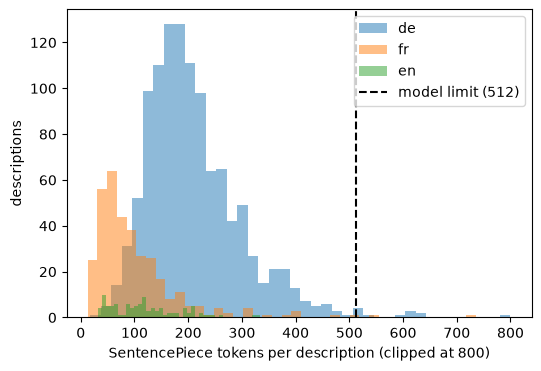

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
for language in ["de", "fr", "en"]:
    part = counts[counts["language"] == language]
    ax.hist(part["sentencepiece"].clip(upper=800), bins=40, alpha=0.5, label=language)
ax.axvline(model.max_seq_length, color="black", ls="--", label="model limit (512)")
ax.set_xlabel("SentencePiece tokens per description (clipped at 800)")
ax.set_ylabel("descriptions")
ax.legend()
plt.show()

**Question.** Which language needs the most tokens per description, and why? What happens to the end of a description that is longer than 512 tokens when it is embedded?

## 3. Semantic similarity across languages

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

texts = [
    "Spielzeugauto aus Kunststoff, mit Rädern",
    "Voiture jouet en matière plastique, avec roues",
    "Toy car of plastics with wheels",
    "Damenschuhe mit Oberteil aus Leder und Laufsohle aus Gummi",
    "Chaussures pour femmes, dessus en cuir, semelle en caoutchouc",
    "Ladies' shoes with textile uppers and rubber soles",
    "Mund-Nasen-Schutzmaske aus Vliesstoff zum Einmalgebrauch",
    "Disposable face mask made of nonwoven fabric",
]
E = model.encode(["passage: " + t for t in texts], normalize_embeddings=True)   # e5 needs a prefix
emb_sim = pd.DataFrame(E @ E.T)
tfidf_sim = pd.DataFrame(cosine_similarity(TfidfVectorizer().fit_transform(texts)))
for i, s in enumerate(texts):
    print(i, s)
emb_sim.round(2).style.background_gradient(cmap="Blues", vmin=0.7, vmax=1)

0 Spielzeugauto aus Kunststoff, mit Rädern
1 Voiture jouet en matière plastique, avec roues
2 Toy car of plastics with wheels
3 Damenschuhe mit Oberteil aus Leder und Laufsohle aus Gummi
4 Chaussures pour femmes, dessus en cuir, semelle en caoutchouc
5 Ladies' shoes with textile uppers and rubber soles
6 Mund-Nasen-Schutzmaske aus Vliesstoff zum Einmalgebrauch
7 Disposable face mask made of nonwoven fabric


,0,1,2,3,4,5,6,7
0,1.000000,0.940000,0.910000,0.850000,0.850000,0.810000,0.870000,0.840000
1,0.940000,1.000000,0.910000,0.820000,0.880000,0.820000,0.860000,0.830000
2,0.910000,0.910000,1.000000,0.770000,0.780000,0.800000,0.800000,0.810000
3,0.850000,0.820000,0.770000,1.000000,0.870000,0.880000,0.840000,0.800000
4,0.850000,0.880000,0.780000,0.870000,1.000000,0.870000,0.870000,0.830000
5,0.810000,0.820000,0.800000,0.880000,0.870000,1.000000,0.810000,0.800000
6,0.870000,0.860000,0.800000,0.840000,0.870000,0.810000,1.000000,0.890000
7,0.840000,0.830000,0.810000,0.800000,0.830000,0.800000,0.890000,1.000000


In [7]:
tfidf_sim.round(2).style.background_gradient(cmap="Blues", vmin=0, vmax=1)

,0,1,2,3,4,5,6,7
0,1.000000,0.000000,0.000000,0.290000,0.000000,0.000000,0.100000,0.000000
1,0.000000,1.000000,0.000000,0.000000,0.170000,0.000000,0.000000,0.000000
2,0.000000,0.000000,1.000000,0.000000,0.000000,0.110000,0.000000,0.120000
3,0.290000,0.000000,0.000000,1.000000,0.000000,0.000000,0.140000,0.000000
4,0.000000,0.170000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
5,0.000000,0.000000,0.110000,0.000000,0.000000,1.000000,0.000000,0.000000
6,0.100000,0.000000,0.000000,0.140000,0.000000,0.000000,1.000000,0.000000
7,0.000000,0.000000,0.120000,0.000000,0.000000,0.000000,0.000000,1.000000


## 4. Where do embeddings and TF-IDF disagree most?

In [8]:
pairs = []
for i in range(len(texts)):
    for j in range(i + 1, len(texts)):
        pairs.append({"i": i, "j": j, "embedding": emb_sim.iloc[i, j], "tfidf": tfidf_sim.iloc[i, j]})
pairs = pd.DataFrame(pairs)
pairs["difference"] = pairs["embedding"] - pairs["tfidf"]
for _, p in pairs.sort_values("difference", ascending=False).head(3).iterrows():
    print(f"{p.embedding:.2f} vs {p.tfidf:.2f}: {texts[int(p.i)]} | {texts[int(p.j)]}")
for _, p in pairs.sort_values("difference").head(2).iterrows():
    print(f"{p.embedding:.2f} vs {p.tfidf:.2f}: {texts[int(p.i)]} | {texts[int(p.j)]}")

0.94 vs 0.00: Spielzeugauto aus Kunststoff, mit Rädern | Voiture jouet en matière plastique, avec roues
0.91 vs 0.00: Spielzeugauto aus Kunststoff, mit Rädern | Toy car of plastics with wheels
0.91 vs 0.00: Voiture jouet en matière plastique, avec roues | Toy car of plastics with wheels
0.85 vs 0.29: Spielzeugauto aus Kunststoff, mit Rädern | Damenschuhe mit Oberteil aus Leder und Laufsohle aus Gummi
0.80 vs 0.11: Toy car of plastics with wheels | Ladies' shoes with textile uppers and rubber soles
